In [1]:
!pip install diffusers transformers accelerate controlnet-aux
!pip install git+https://github.com/openai/CLIP.git
!pip install segment-anything

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.4/290.4 kB 1.9 MB/s eta 0:00:0000:0100:01
  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-6hq06o89
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-6hq06o89
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 555.6 kB/s eta 0:00:000:00:01
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369490 sha256=a6caaf62f3a0542a9eb5747f5fb598ccf4307a9e40c14b2e95f2f0ffda066403
  Stored in directory: /tmp/pip-ephem-wheel-cache-wefkit80/wheels/35/3e/df/3d24cbfb3b6a06f17a2bfd7d1138900d4365d9028aa8f6e92f
Successfully built clip


In [2]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
from diffusers import UniPCMultistepScheduler
from transformers import pipeline as hf_pipeline
from PIL import Image
import requests
from io import BytesIO
import torch
import numpy as np

print("All imports done!")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


All imports done!


In [3]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-depth",
    torch_dtype=torch.float16
)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16
).to("cuda")

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)
pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()

print("Pipeline loaded!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:202: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Pipeline loaded!


In [4]:
depth_estimator = hf_pipeline(
    "depth-estimation",
    model="LiheYoung/depth-anything-base-hf"
)

print("Depth estimator loaded!")

config.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/390M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

The image processor of type `DPTImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Depth estimator loaded!


In [5]:
!pip install diffusers transformers accelerate controlnet-aux xformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 9.6 MB/s eta 0:00:00a 0:00:01


Image loaded!


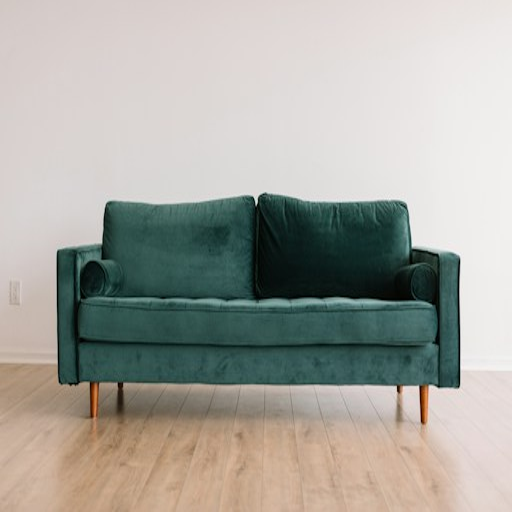

In [6]:
url = "https://images.unsplash.com/photo-1555041469-a586c61ea9bc?w=512"
response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"})
image = Image.open(BytesIO(response.content)).convert("RGB")
image = image.resize((512, 512))

print("Image loaded!")
image

Depth map ready!


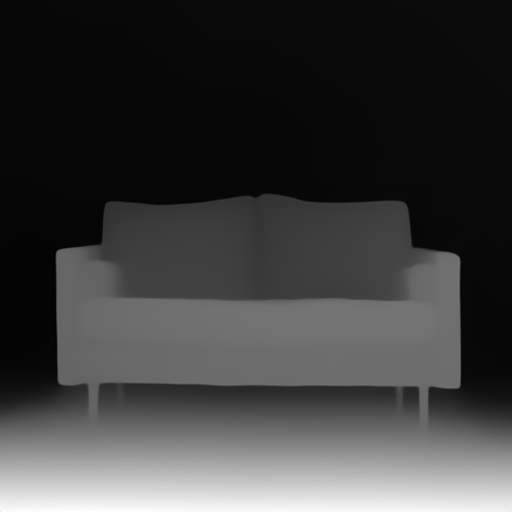

In [7]:
depth_result = depth_estimator(image)
depth_map = depth_result["depth"].resize((512, 512))

print("Depth map ready!")
depth_map

  0%|          | 0/20 [00:00<?, ?it/s]

Generation complete!


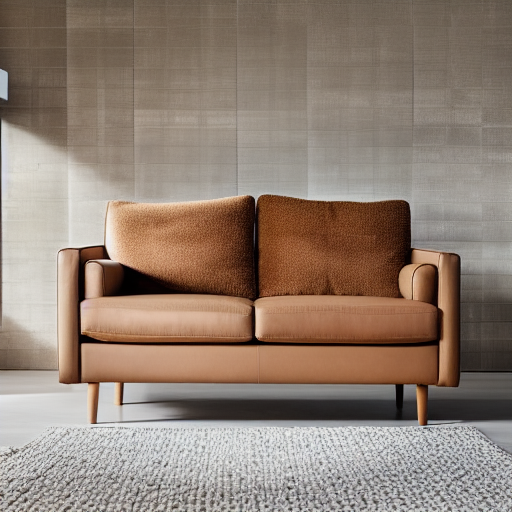

In [8]:
result = pipe(
    prompt="a modern scandinavian living room, \
            warm lighting, minimalist furniture, \
            hardwood floors, photorealistic, \
            interior design magazine, 8k",
    
    negative_prompt="ugly, blurry, bad proportions, \
                     unrealistic, cartoon, drawing, \
                     dark, gloomy",
    
    image=depth_map,
    num_inference_steps=20,
    guidance_scale=7.5
).images[0]

print("Generation complete!")
result

In [9]:
styles = [
    "a modern scandinavian living room, warm lighting, minimalist, photorealistic",
    "a luxurious royal living room, gold accents, velvet furniture, photorealistic",
    "an industrial loft, exposed brick walls, metal fixtures, photorealistic",
    "a bohemian cozy room, warm earth tones, plants everywhere, photorealistic"
]

results = []

for style in styles:
    output = pipe(
        prompt=style,
        negative_prompt="ugly, blurry, unrealistic, cartoon",
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    results.append(output)
    print(f"Generated: {style[:40]}...")

print("All styles generated!")

  0%|          | 0/20 [00:00<?, ?it/s]

Generated: a modern scandinavian living room, warm ...


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: a luxurious royal living room, gold acce...


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: an industrial loft, exposed brick walls,...


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: a bohemian cozy room, warm earth tones, ...
All styles generated!


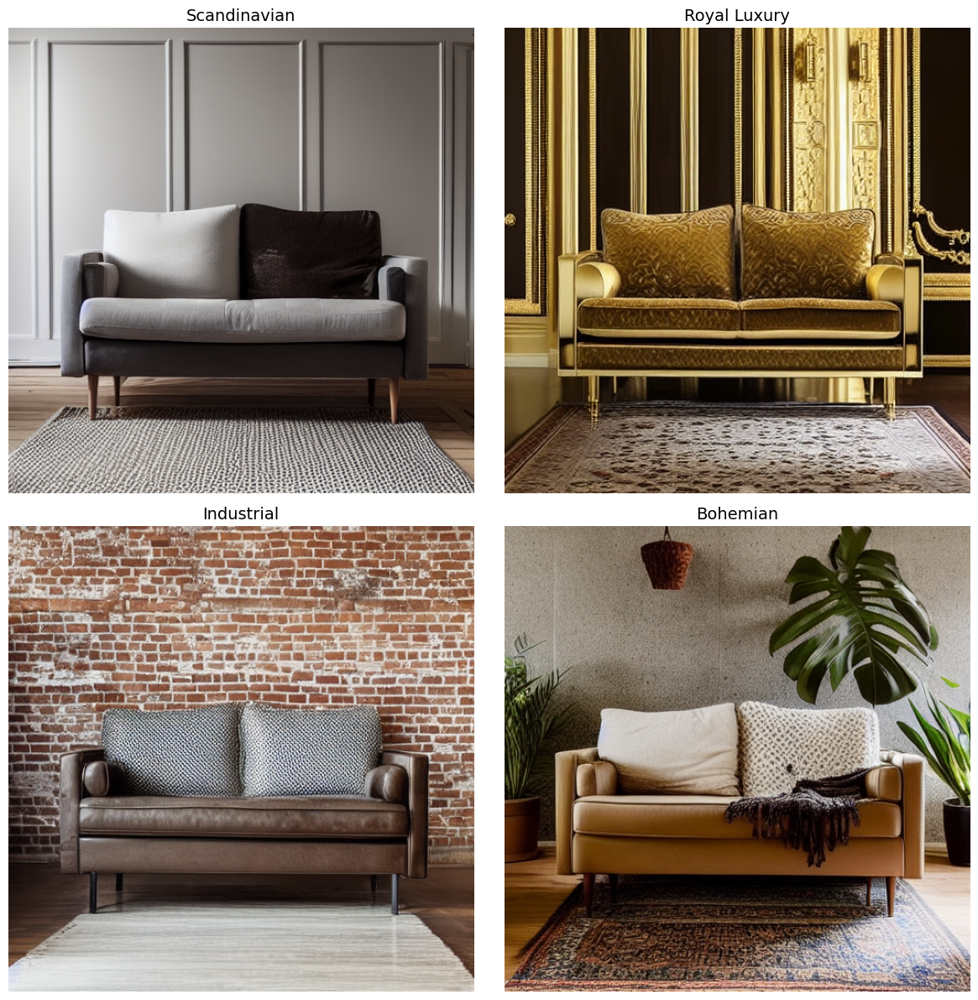

Saved!


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
style_names = ["Scandinavian", "Royal Luxury", "Industrial", "Bohemian"]

for idx, (ax, result, name) in enumerate(zip(axes.flatten(), results, style_names)):
    ax.imshow(result)
    ax.set_title(name, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.savefig("style_comparison.png")
plt.show()
print("Saved!")

In [11]:
print(pipe)       # Should show StableDiffusionControlNetPipeline
print(depth_map)  # Should show PIL Image info
print(image)      # Should show PIL Image info

StableDiffusionControlNetPipeline {
  "_class_name": "StableDiffusionControlNetPipeline",
  "_diffusers_version": "0.36.0",
  "_name_or_path": "runwayml/stable-diffusion-v1-5",
  "controlnet": [
    "diffusers",
    "ControlNetModel"
  ],
  "feature_extractor": [
    "transformers",
    "CLIPImageProcessor"
  ],
  "image_encoder": [
    null,
    null
  ],
  "requires_safety_checker": true,
  "safety_checker": [
    "stable_diffusion",
    "StableDiffusionSafetyChecker"
  ],
  "scheduler": [
    "diffusers",
    "UniPCMultistepScheduler"
  ],
  "text_encoder": [
    "transformers",
    "CLIPTextModel"
  ],
  "tokenizer": [
    "transformers",
    "CLIPTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderKL"
  ]
}

<PIL.Image.Image image mode=L size=512x512 at 0x7AB2C48832F0>
<PIL.Image.Image image mode=RGB size=512x512 at 0x7AB2C46B1A90>


In [12]:
!pip install segment-anything
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

from segment_anything import SamPredictor, sam_model_registry
import numpy as np

sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to("cuda")
predictor = SamPredictor(sam)

print("SAM loaded!")

SAM loaded!


In [13]:
import numpy as np

# Convert image to numpy array
image_np = np.array(image)

# MUST set image before predicting
predictor.set_image(image_np)

# Multiple click points to cover full sofa
click_points = np.array([
    [256, 250],
    [256, 300],
    [256, 350],
])
click_labels = np.array([1, 1, 1])

masks, scores, logits = predictor.predict(
    point_coords=click_points,
    point_labels=click_labels,
    multimask_output=False
)

print(f"Mask generated! Confidence: {scores[0]:.3f}")

Mask generated! Confidence: 0.944


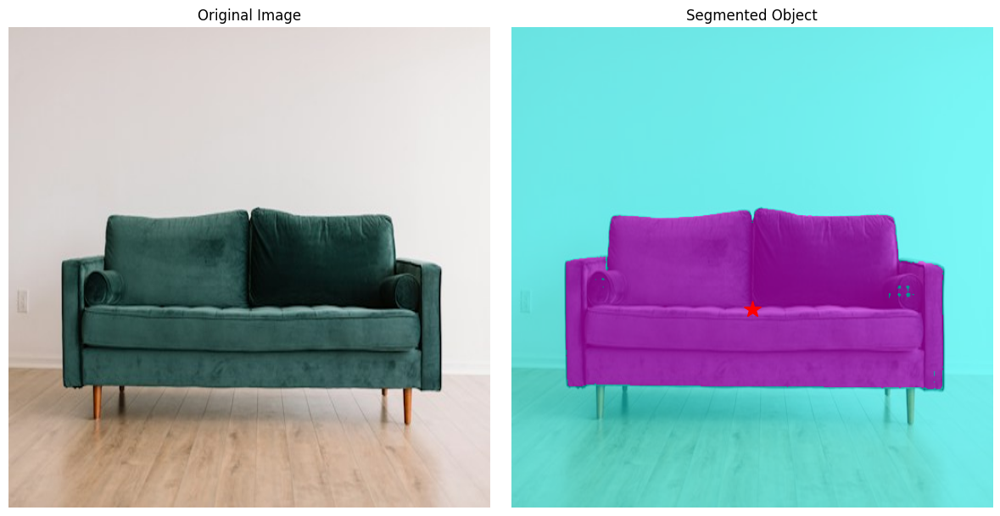

Segmentation visualized!


In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Original image
axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

# Image with mask overlay
axes[1].imshow(image)
axes[1].imshow(masks[0], alpha=0.5, cmap="cool")
axes[1].plot(256, 300, "r*", markersize=15)  # Show click point
axes[1].set_title("Segmented Object")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("sam_segmentation.png")
plt.show()
print("Segmentation visualized!")

  0%|          | 0/20 [00:00<?, ?it/s]

Done!


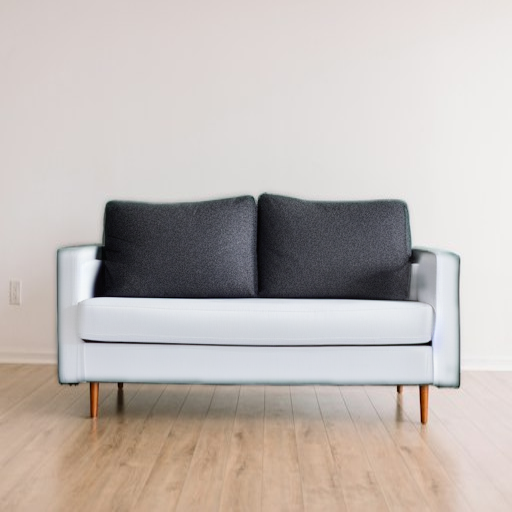

In [15]:
from PIL import Image, ImageFilter
import numpy as np

mask_image = Image.fromarray((masks[0] * 255).astype(np.uint8))
mask_blurred = mask_image.filter(ImageFilter.GaussianBlur(radius=3))

depth_result = depth_estimator(image)
depth_map = depth_result["depth"].resize((512, 512))

result_masked = pipe(
    prompt="a clean modern white fabric sofa, \
            scandinavian style, wooden legs, \
            photorealistic, interior design magazine",
    negative_prompt="ugly, blurry, unrealistic, \
                     cartoon, gold, gaudy, shiny",
    image=depth_map,
    num_inference_steps=20,
    guidance_scale=7.5
).images[0]

result_composite = Image.composite(result_masked, image, mask_blurred)
print("Done!")
result_composite

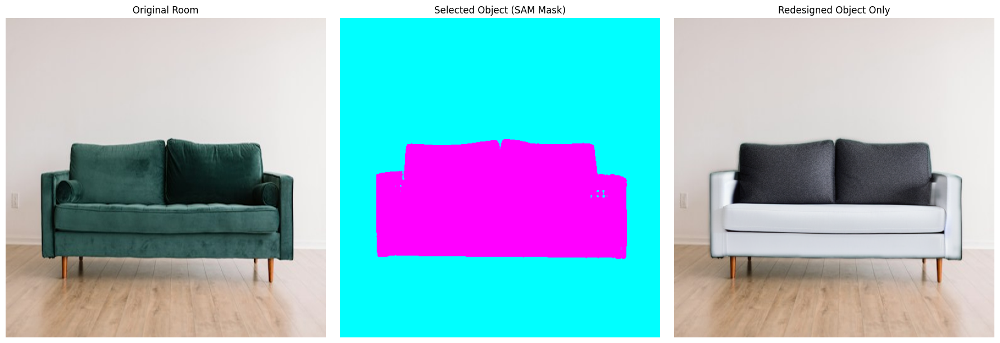

Saved!


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title("Original Room")
axes[0].axis("off")

axes[1].imshow(masks[0], cmap="cool")
axes[1].set_title("Selected Object (SAM Mask)")
axes[1].axis("off")

axes[2].imshow(result_composite)
axes[2].set_title("Redesigned Object Only")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("object_redesign.png")
plt.show()
print("Saved!")

In [17]:
!pip install git+https://github.com/openai/CLIP.git

import clip
import torch
from PIL import Image
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)

print(f"CLIP loaded on {device}!")

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-117eub6f
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-117eub6f
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done


100%|███████████████████████████████████████| 338M/338M [00:06<00:00, 57.5MiB/s]


CLIP loaded on cuda!


In [18]:
def encode_image_style(img):
    """Takes a PIL image, returns its CLIP embedding"""
    image_tensor = clip_preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        embedding = clip_model.encode_image(image_tensor)
    return embedding.cpu()

# Test it on your existing result
embedding = encode_image_style(result_composite)
print(f"Style embedding shape: {embedding.shape}")
print("Encoder working!")

Style embedding shape: torch.Size([1, 512])
Encoder working!


In [19]:
# This simulates a user liking and disliking certain styles
liked_images = []
disliked_images = []

def like_image(img):
    liked_images.append(encode_image_style(img))
    print(f" Liked! Total liked: {len(liked_images)}")

def dislike_image(img):
    disliked_images.append(encode_image_style(img))
    print(f" Disliked! Total disliked: {len(disliked_images)}")

def get_style_profile():
    """Builds user style profile from liked/disliked images"""
    if not liked_images:
        return None
    
    liked_mean = torch.stack(liked_images).mean(0)
    
    if disliked_images:
        disliked_mean = torch.stack(disliked_images).mean(0)
        # Pull toward liked, push away from disliked
        profile = liked_mean - (disliked_mean * 0.3)
    else:
        profile = liked_mean
    
    return profile

print("Preference system ready!")

Preference system ready!


In [20]:
# Generate 4 different styles to react to
test_styles = [
    ("scandinavian", "modern scandinavian room, white walls, minimal, photorealistic"),
    ("industrial", "industrial loft, exposed brick, dark tones, photorealistic"),
    ("bohemian", "bohemian room, earth tones, plants, warm, photorealistic"),
    ("luxury", "luxury room, gold accents, velvet, chandeliers, photorealistic"),
]

generated_styles = {}

for name, prompt in test_styles:
    output = pipe(
        prompt=prompt,
        negative_prompt="ugly, blurry, cartoon, unrealistic",
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    generated_styles[name] = output
    print(f"Generated: {name}")

print("All styles ready!")

  0%|          | 0/20 [00:00<?, ?it/s]

Generated: scandinavian


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: industrial


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: bohemian


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: luxury
All styles ready!


In [21]:
# Simulate user preferences
# User likes clean minimal styles
like_image(generated_styles["scandinavian"])
like_image(generated_styles["bohemian"])

# User dislikes dark heavy styles  
dislike_image(generated_styles["industrial"])
dislike_image(generated_styles["luxury"])

# Build their style profile
profile = get_style_profile()
print(f"Style profile shape: {profile.shape}")
print("User taste profile built!")

 Liked! Total liked: 1
 Liked! Total liked: 2
 Disliked! Total disliked: 1
 Disliked! Total disliked: 2
Style profile shape: torch.Size([1, 512])
User taste profile built!


In [22]:
# Define style anchors
style_anchors = [
    "scandinavian minimalist interior",
    "industrial dark loft interior",
    "bohemian warm cozy interior",
    "luxury royal opulent interior",
    "modern clean contemporary interior",
    "rustic farmhouse interior",
    "japandi zen minimal interior"
]

# Generate 4 different styles to react to
test_styles = [
    ("scandinavian", "modern scandinavian room, white walls, minimal, photorealistic"),
    ("industrial", "industrial loft, exposed brick, dark tones, photorealistic"),
    ("bohemian", "bohemian room, earth tones, plants, warm, photorealistic"),
    ("luxury", "luxury room, gold accents, velvet, chandeliers, photorealistic"),
]

generated_styles = {}

for name, prompt in test_styles:
    output = pipe(
        prompt=prompt,
        negative_prompt="ugly, blurry, cartoon, unrealistic",
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    generated_styles[name] = output
    print(f"Generated: {name}")

print("All styles ready!")

# ---- THIS PART WAS MISSING ----
# Encode style anchors into CLIP text embeddings
text_tokens = clip.tokenize(style_anchors).to(device)
with torch.no_grad():
    text_embeddings = clip_model.encode_text(text_tokens).cpu()

# Fix tensor shapes
profile_flat = profile.squeeze().float()
text_embeddings = text_embeddings.float()

# Find closest style anchor to user profile
similarities = torch.cosine_similarity(
    profile_flat.unsqueeze(0).expand_as(text_embeddings),
    text_embeddings
)

best_match_idx = similarities.argmax().item()
best_style = style_anchors[best_match_idx]

print(f"Your taste profile matches: '{best_style}'")
print(f"Similarity scores: {similarities.tolist()}")

  0%|          | 0/20 [00:00<?, ?it/s]

Generated: scandinavian


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: industrial


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: bohemian


  0%|          | 0/20 [00:00<?, ?it/s]

Generated: luxury
All styles ready!
Your taste profile matches: 'scandinavian minimalist interior'
Similarity scores: [0.2963731288909912, 0.22220486402511597, 0.24181166291236877, 0.2147674560546875, 0.2524452209472656, 0.23865985870361328, 0.2517639100551605]


  0%|          | 0/20 [00:00<?, ?it/s]

Generated with personalized prompt: a scandinavian minimalist interior,                         photorealistic,                         interior design magazine, 8k,                         warm lighting


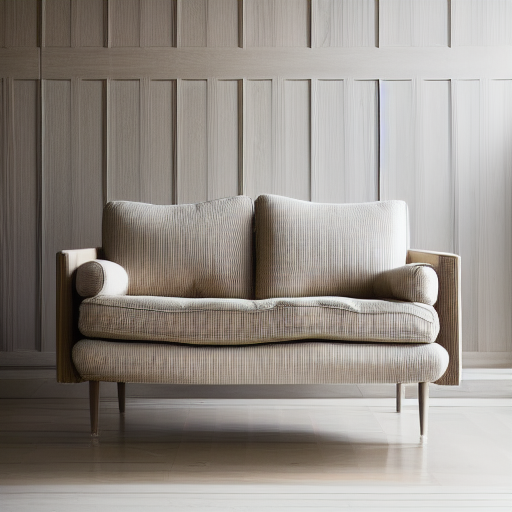

In [23]:
personalized_prompt = f"a {best_style}, \
                        photorealistic, \
                        interior design magazine, 8k, \
                        warm lighting"

personalized_result = pipe(
    prompt=personalized_prompt,
    negative_prompt="ugly, blurry, cartoon, unrealistic",
    image=depth_map,
    num_inference_steps=20,
    guidance_scale=7.5
).images[0]

print(f"Generated with personalized prompt: {personalized_prompt}")
personalized_result

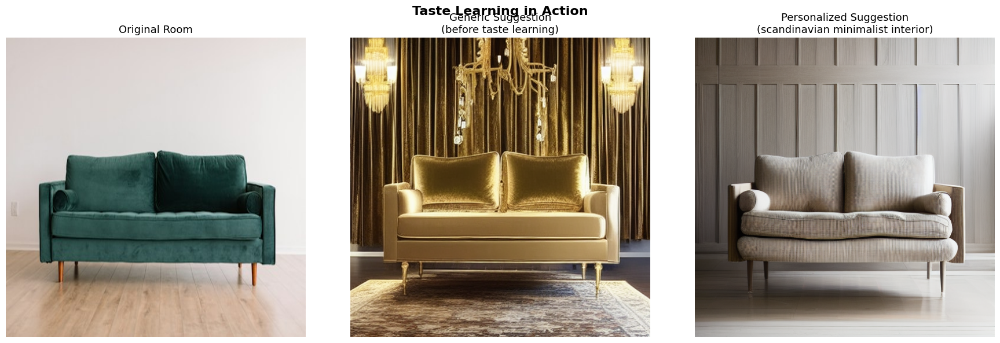

Saved!


In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title("Original Room", fontsize=13)
axes[0].axis("off")

axes[1].imshow(generated_styles["luxury"])
axes[1].set_title("Generic Suggestion\n(before taste learning)", fontsize=13)
axes[1].axis("off")

axes[2].imshow(personalized_result)
axes[2].set_title(f"Personalized Suggestion\n({best_style})", fontsize=13)
axes[2].axis("off")

plt.suptitle("Taste Learning in Action", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("taste_learning_demo.png")
plt.show()
print("Saved!")

In [25]:
from diffusers import StableDiffusionInpaintPipeline

inpaint_pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16
).to("cuda")

inpaint_pipe.enable_model_cpu_offload()
inpaint_pipe.enable_attention_slicing()

print("Inpainting pipeline loaded!")

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Inpainting pipeline loaded!


In [26]:
def inpaint_region(image, mask, prompt, negative_prompt=None):
    """
    image: PIL RGB image
    mask: PIL grayscale mask — white = region to change, black = keep
    prompt: what to generate in the masked region
    """
    image = image.resize((512, 512))
    mask = mask.resize((512, 512))
    
    result = inpaint_pipe(
        prompt=prompt,
        negative_prompt=negative_prompt or "ugly, blurry, unrealistic",
        image=image,
        mask_image=mask,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    
    return result

In [51]:
from PIL import Image, ImageFilter
import numpy as np

style_anchors = [
    "scandinavian minimalist interior",
    "industrial dark loft interior",
    "bohemian warm cozy interior",
    "luxury royal opulent interior",
    "modern clean contemporary interior",
    "rustic farmhouse interior",
    "japandi zen minimal interior"
]

def full_pipeline(input_image, user_id="default",
                  click_point=None, base_prompt="a beautiful room",
                  custom_prompt=None, operation="redesign",
                  furniture_prompt=None):

    print(f"Processing for user: {user_id}")

    # Step 1 — Resize
    input_image = input_image.resize((512, 512))

    # Step 2 — Build final prompt
    if custom_prompt:
        final_prompt = custom_prompt
    elif furniture_prompt:
        final_prompt = f"{base_prompt}, {furniture_prompt}, \
                        photorealistic, interior design magazine"
    else:
        final_prompt = f"{base_prompt}, photorealistic, \
                        interior design magazine"

    # Step 3 — Apply taste learning if profile exists and no custom prompt
    if liked_images and not custom_prompt:
        profile = get_style_profile()
        profile_flat = profile.squeeze().float()
        text_tokens = clip.tokenize(style_anchors).to(device)
        with torch.no_grad():
            text_embeddings = clip_model.encode_text(
                               text_tokens).cpu().float()
        similarities = torch.cosine_similarity(
            profile_flat.unsqueeze(0).expand_as(text_embeddings),
            text_embeddings
        )
        style_modifier = style_anchors[similarities.argmax().item()]
        final_prompt = f"{final_prompt}, {style_modifier}"

    print(f" Final prompt: {final_prompt}")

    # Step 4 — Inpaint specific region
    if operation == "inpaint" and click_point is not None:
        image_np = np.array(input_image)
        predictor.set_image(image_np)
        click_points = np.array([click_point])
        click_labels = np.array([1])
        masks, _, _ = predictor.predict(
            point_coords=click_points,
            point_labels=click_labels,
            multimask_output=False
        )
        mask_image = Image.fromarray(
                     (masks[0] * 255).astype(np.uint8))
        result = inpaint_pipe(
            prompt=final_prompt,
            negative_prompt="ugly, blurry, cartoon, unrealistic",
            image=input_image,
            mask_image=mask_image,
            num_inference_steps=20,
            guidance_scale=7.5
        ).images[0]
        print(" Inpainting complete")
        return result

    # Step 5 — Add furniture via prompt + depth conditioning
    # Club add_furniture and inpaint into one "modify" operation
    elif operation == "modify":
    
        if furniture_prompt:
            final_prompt = f"{furniture_prompt}, \
                        photorealistic, interior design magazine, \
                        high quality, realistic lighting, \
                        seamlessly integrated into the room"
        elif custom_prompt:
            final_prompt = custom_prompt
        else:
            final_prompt = f"{base_prompt}, photorealistic"
    
        if click_point is not None:
        # SAM mask the clicked region
            image_np = np.array(input_image)
            predictor.set_image(image_np)
            click_points = np.array([
                click_point,
                [click_point[0]-40, click_point[1]],
                [click_point[0]+40, click_point[1]],
                [click_point[0], click_point[1]-40],
                [click_point[0], click_point[1]+40],
            ])
            click_labels = np.array([1, 1, 1, 1, 1])
            masks, _, _ = predictor.predict(
                point_coords=click_points,
                point_labels=click_labels,
                multimask_output=False
            )
            mask_image = Image.fromarray(
                     (masks[0] * 255).astype(np.uint8))
            mask_blurred = mask_image.filter(
                       ImageFilter.GaussianBlur(radius=8))
        else:
        # No click — mask bottom third
            mask_array = np.zeros((512, 512), dtype=np.uint8)
            mask_array[340:, :] = 255
            mask_image = Image.fromarray(mask_array)
            mask_blurred = mask_image.filter(
                       ImageFilter.GaussianBlur(radius=12))
    
        result = inpaint_pipe(
            prompt=final_prompt,
            negative_prompt="ugly, blurry, cartoon, unrealistic, \
                         rough edges, visible seams",
            image=input_image,
            mask_image=mask_blurred,
            num_inference_steps=30,
            guidance_scale=9.0
        ).images[0]
    
        print("✅ Modify complete")
        return result

    # Step 6 — Default full room redesign
    else:
        depth_result = depth_estimator(input_image)
        depth_map = depth_result["depth"].resize((512, 512))

        if click_point is not None:
            image_np = np.array(input_image)
            predictor.set_image(image_np)
            click_points = np.array([
                click_point,
                [click_point[0], click_point[1]-30],
                [click_point[0], click_point[1]+30]
            ])
            click_labels = np.array([1, 1, 1])
            masks, _, _ = predictor.predict(
                point_coords=click_points,
                point_labels=click_labels,
                multimask_output=False
            )
            mask_image = Image.fromarray(
                         (masks[0] * 255).astype(np.uint8))
            mask_blurred = mask_image.filter(
                           ImageFilter.GaussianBlur(radius=3))
        else:
            mask_blurred = None

        result = pipe(
            prompt=final_prompt,
            negative_prompt="ugly, blurry, cartoon, unrealistic",
            image=depth_map,
            num_inference_steps=20,
            guidance_scale=7.5
        ).images[0]

        if mask_blurred is not None:
            result = Image.composite(result, input_image, mask_blurred)

        print(" Pipeline completed")
        return result

print("full_pipeline ready")

full_pipeline ready


Processing for user: test
 Final prompt: a beautiful room, a tall modern floor lamp with warm glow,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Modify complete


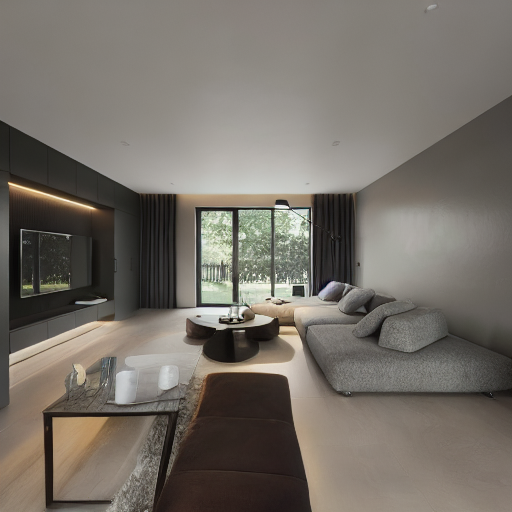

Processing for user: test_user
 Final prompt: Scandinavian interior design, minimalist furniture, light natural wood, neutral colours, soft textiles, natural lighting, clean lines, and a cozy atmosphere, Add a floor lamp in the selected empty corner.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 06:38:10] "POST /generate HTTP/1.1" 200 -


 Pipeline completed
Processing for user: test_user
 Final prompt: Scandinavian interior design, minimalist furniture, light natural wood, neutral colours, soft textiles, natural lighting, clean lines, and a cozy atmosphere, Add a floor lamp in the selected empty corner.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

...

 Pipeline completed
Processing for user: test_user
 Final prompt: Scandinavian interior design, minimalist furniture, light natural wood, neutral colours, soft textiles, natural lighting, clean lines, and a cozy atmosphere, Add a clearly visible, modern three-seater red sofa and a large wooden bookshelf filled with books to the selected area. Make both objects realistic, correctly scaled, and naturally integrated into the room with accurate perspective, lighting, and shadows. Preserve the existing walls, windows, doors, flooring, and camera angle. Do not replace or redesign the entire room.,                         photorealistic, interior design magazine, scandinavian minimalist interior


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['preserve the existing walls , windows , doors , flooring , and camera angle . do not replace or redesign the entire room ., photorealistic , interior design magazine , scandinavian minimalist interior']


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 06:49:57] "POST /generate HTTP/1.1" 200 -


 Pipeline completed


In [52]:
# Click on an empty area where you want furniture added
# Bottom left corner of the room
result = full_pipeline(
    input_image=test_img,
    user_id="test",
    operation="modify",
    furniture_prompt="a tall modern floor lamp with warm glow",
    click_point=[100, 400]  # bottom left corner
)

result

=== TEST 1: Full Room ===
Processing for user: student_1
 Final prompt: same room with white walls,                  light grey sofa, wooden floor,                  bright natural lighting, minimal decor,                  no wood panels, open airy space,                  scandinavian apartment, photorealistic,                         interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

 Pipeline completed
=== TEST 2: Object Only ===
Processing for user: student_1
 Final prompt: a modern sofa, clean fabric,                  scandinavian style, wooden legs, photorealistic,                         interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

 Pipeline completed


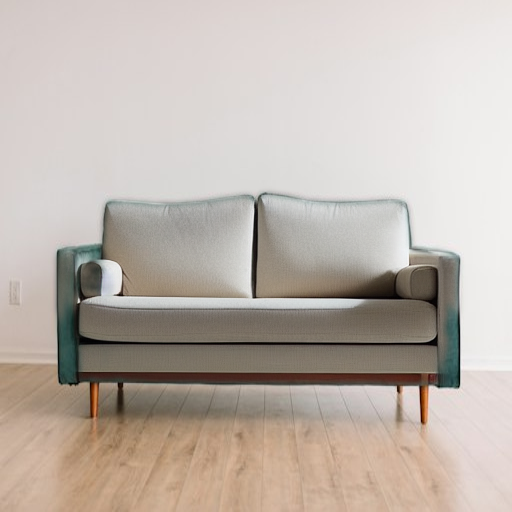

In [28]:
# Test 1 — Full room redesign with better prompt
print("=== TEST 1: Full Room ===")
result1 = full_pipeline(
    input_image=image,
    user_id="student_1",
    base_prompt="same room with white walls, \
                 light grey sofa, wooden floor, \
                 bright natural lighting, minimal decor, \
                 no wood panels, open airy space, \
                 scandinavian apartment"
)
result1
# Test 2 — Object only (separate cell)
print("=== TEST 2: Object Only ===")
result2 = full_pipeline(
    input_image=image,
    user_id="student_1",
    click_point=[256, 280],
    base_prompt="a modern sofa, clean fabric, \
                 scandinavian style, wooden legs"
)
result2

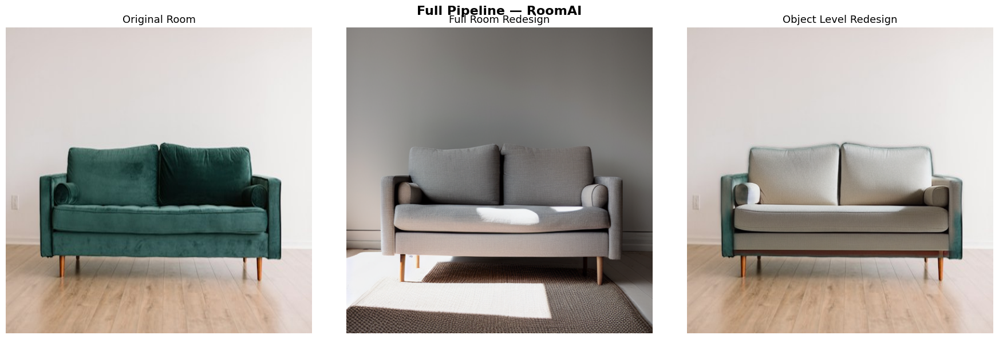

 Saved as final_pipeline_demo.png


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title("Original Room", fontsize=13)
axes[0].axis("off")

axes[1].imshow(result1)
axes[1].set_title("Full Room Redesign", fontsize=13)
axes[1].axis("off")

axes[2].imshow(result2)
axes[2].set_title("Object Level Redesign", fontsize=13)
axes[2].axis("off")

plt.suptitle("Full Pipeline — RoomAI", 
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("final_pipeline_demo.png")
plt.show()
print(" Saved as final_pipeline_demo.png")

In [30]:
guidance_scales = [5.0, 7.5, 10.0, 12.0]
guidance_results = []

for gs in guidance_scales:
    output = pipe(
        prompt="a modern scandinavian living room, \
                warm lighting, minimalist furniture, \
                hardwood floors, photorealistic",
        negative_prompt="ugly, blurry, cartoon, unrealistic",
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=gs
    ).images[0]
    guidance_results.append(output)
    print(f"Generated guidance_scale={gs}")

print("All done!")

  0%|          | 0/20 [00:00<?, ?it/s]

Generated guidance_scale=5.0


  0%|          | 0/20 [00:00<?, ?it/s]

Generated guidance_scale=7.5


  0%|          | 0/20 [00:00<?, ?it/s]

Generated guidance_scale=10.0


  0%|          | 0/20 [00:00<?, ?it/s]

Generated guidance_scale=12.0
All done!


In [31]:
inference_steps = [10, 20, 30, 50]
steps_results = []

for steps in inference_steps:
    output = pipe(
        prompt="a modern scandinavian living room, \
                warm lighting, minimalist furniture, \
                hardwood floors, photorealistic",
        negative_prompt="ugly, blurry, cartoon, unrealistic",
        image=depth_map,
        num_inference_steps=steps,
        guidance_scale=7.5
    ).images[0]
    steps_results.append(output)
    print(f"Generated steps={steps}")

print("All done!")

  0%|          | 0/10 [00:00<?, ?it/s]

Generated steps=10


  0%|          | 0/20 [00:00<?, ?it/s]

Generated steps=20


  0%|          | 0/30 [00:00<?, ?it/s]

Generated steps=30


  0%|          | 0/50 [00:00<?, ?it/s]

Generated steps=50
All done!


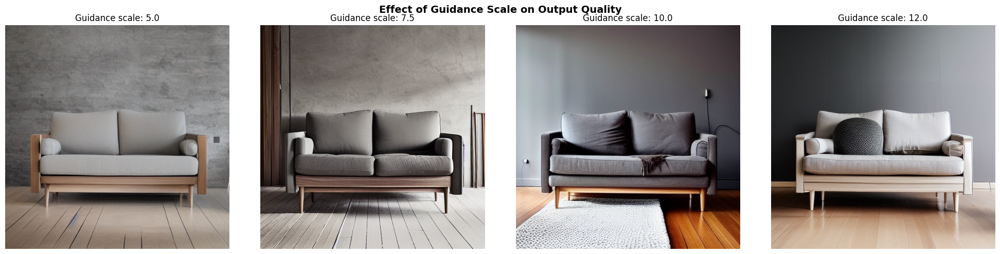

Saved!


In [32]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, (ax, result, gs) in enumerate(
        zip(axes, guidance_results, guidance_scales)):
    ax.imshow(result)
    ax.set_title(f"Guidance scale: {gs}", fontsize=12)
    ax.axis("off")

plt.suptitle("Effect of Guidance Scale on Output Quality",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("guidance_scale_comparison.png")
plt.show()
print("Saved!")

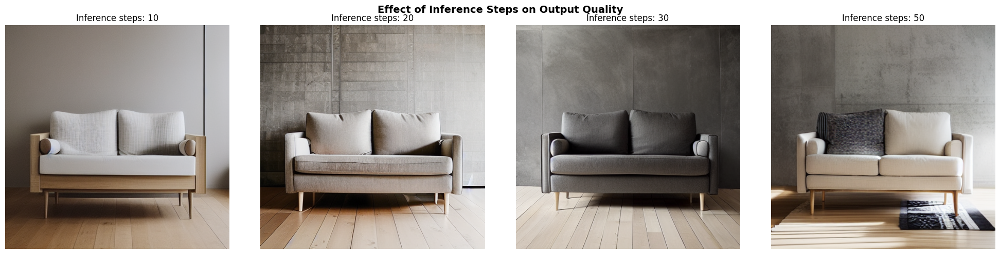

Saved!


In [33]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, (ax, result, steps) in enumerate(
        zip(axes, steps_results, inference_steps)):
    ax.imshow(result)
    ax.set_title(f"Inference steps: {steps}", fontsize=12)
    ax.axis("off")

plt.suptitle("Effect of Inference Steps on Output Quality",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("inference_steps_comparison.png")
plt.show()
print("Saved!")

Processing for user: test
 Final prompt: a modern living room, a sleek white modern sofa with cushions,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

 Inpainting complete


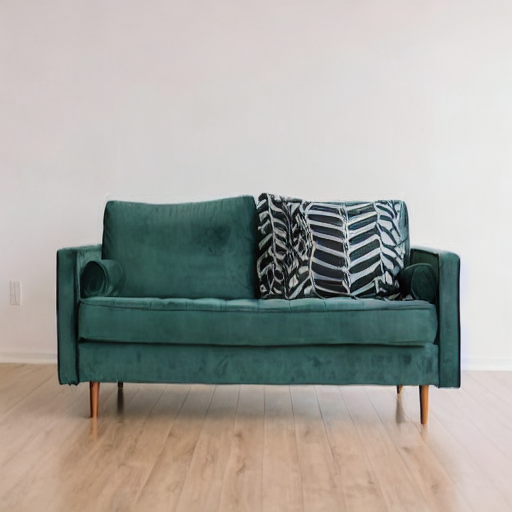

In [34]:
# Quick test — inpaint the sofa region with a new furniture prompt
test_result = full_pipeline(
    input_image=image,
    user_id="test",
    click_point=[256, 280],
    base_prompt="a modern living room",
    furniture_prompt="a sleek white modern sofa with cushions",
    operation="inpaint"
)

test_result

In [38]:
!pip install flask pyngrok

from pyngrok import ngrok
from flask import Flask, request, send_file
from PIL import Image
import io
import threading

ngrok.set_auth_token("3CCYurDubeOH6njtLkr8VZAkAgV_6nbQyL1ZUncA3hWVTe5u4")

app_flask = Flask(__name__)

@app_flask.route("/generate", methods=["POST"])
def generate():
    try:
        file = request.files["file"]
        base_prompt = request.form.get("base_prompt",
                      "a modern scandinavian living room, \
                       warm lighting, photorealistic")
        custom_prompt = request.form.get("custom_prompt", None)
        furniture_prompt = request.form.get("furniture_prompt", None)
        operation = request.form.get("operation", "redesign")
        click_x = request.form.get("click_x", None)
        click_y = request.form.get("click_y", None)
        user_id = request.form.get("user_id", "default")

        image = Image.open(file.stream).convert("RGB")
        click_point = [int(click_x), int(click_y)] \
                      if click_x and click_y else None

        result = full_pipeline(
            input_image=image,
            user_id=user_id,
            click_point=click_point,
            base_prompt=base_prompt,
            custom_prompt=custom_prompt,
            operation=operation,
            furniture_prompt=furniture_prompt
        )

        buf = io.BytesIO()
        result.save(buf, format="JPEG")
        buf.seek(0)
        return send_file(buf, mimetype="image/jpeg")

    except Exception as e:
        return {"error": str(e)}, 500

public_url = ngrok.connect(5000)
print("NGROK URL:", public_url)
print("Share this URL with Person 2!")

threading.Thread(
    target=lambda: app_flask.run(port=5000, use_reloader=False)
).start()

NGROK URL: NgrokTunnel: "https://wackiness-spoils-manhunt.ngrok-free.dev" -> "http://localhost:5000"
Share this URL with Person 2!
 * Serving Flask app '__main__'
 * Debug mode: off


Address already in use
Port 5000 is in use by another program. Either identify and stop that program, or start the server with a different port.


Processing for user: test_user
 Final prompt: Scandinavian interior design, minimalist furniture, light natural wood, neutral colours, soft textiles, natural lighting, clean lines, and a cozy atmosphere, Add a cozy reading nook with warm lighting and wooden furniture.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 05:38:34] "POST /generate HTTP/1.1" 200 -


...

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 05:43:04] "POST /generate HTTP/1.1" 200 -


 Furniture addition complete
Processing for user: test_user
 Final prompt: Scandinavian interior design, minimalist furniture, light natural wood, neutral colours, soft textiles, natural lighting, clean lines, and a cozy atmosphere, Add a clearly visible red three-seater sofa and a large wooden bookshelf. Preserve the original walls, windows, floor, and camera angle.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 05:47:25] "POST /generate HTTP/1.1" 200 -


 Furniture addition complete


Processing for user: test
 Final prompt: a modern living room, add a tall floor lamp in the corner,                       add a coffee table in front of the sofa,                       add decorative plants near the window,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

 Furniture addition complete


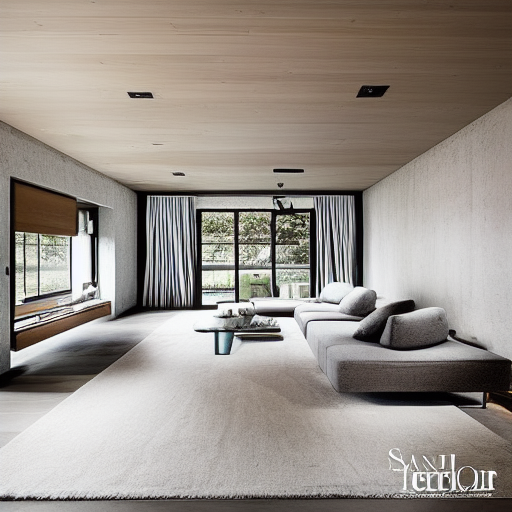

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Processing for user: test_user
 Final prompt: Royal luxury interior design, elegant furniture, rich colours, sophisticated fabrics, ornate details, refined finishes, and a luxurious atmosphere, Redesign this room in a luxurious royal style with rich textures, elegant furniture, and gold accents.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 05:49:15] "POST /generate HTTP/1.1" 200 -


 Furniture addition complete
Processing for user: test_user
 Final prompt: Industrial interior design, exposed materials, metal accents, concrete textures, dark neutral colours, functional furniture, and an urban loft aesthetic, Redesign this room in an industrial style with black metal details, warm wood, exposed textures, and functional furniture.,                         photorealistic, interior design magazine, scandinavian minimalist interior


  0%|          | 0/20 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [11/Oct/2026 05:51:01] "POST /generate HTTP/1.1" 200 -


 Furniture addition complete


In [39]:
# Test add_furniture operation
test_img = Image.open(
    os.path.join(image_dir, image_files[0])
).convert("RGB").resize((512,512))

result = full_pipeline(
    input_image=test_img,
    user_id="test",
    operation="add_furniture",
    base_prompt="a modern living room",
    furniture_prompt="add a tall floor lamp in the corner, \
                      add a coffee table in front of the sofa, \
                      add decorative plants near the window"
)

result

In [36]:
import os
import json

image_dir = "/kaggle/input/datasets/anaghamr22/roomai-test-sets/roomai-test-set"
image_files = os.listdir(image_dir)

dataset_log = []
room_types = {}

# Manually assign room types based on filename or folder
# Easiest: name your files living_room_01.jpg, bedroom_01.jpg etc
for f in image_files:
    if "living" in f:
        room_type = "living room"
    elif "bedroom" in f or "bed" in f:
        room_type = "bedroom"
    elif "dining" in f:
        room_type = "dining room"
    else:
        room_type = "other"
    
    dataset_log.append({
        "filename": f,
        "room_type": room_type,
        "source": "Unsplash",
        "license": "Unsplash License (free, no attribution required)"
    })
    room_types[room_type] = room_types.get(room_type, 0) + 1

print(f"Total images: {len(dataset_log)}")
print(f"Room type breakdown: {room_types}")
print(f"Source: Unsplash")
print(f"License: Unsplash License")

# Save log
with open("dataset_log.json", "w") as f:
    json.dump(dataset_log, f, indent=2)
print("Dataset log saved!")

Total images: 29
Room type breakdown: {'living room': 12, 'dining room': 7, 'bedroom': 10}
Source: Unsplash
License: Unsplash License
Dataset log saved!


In [37]:
from PIL import Image
import numpy as np
from scipy.stats import pearsonr
import os

def get_depth_map(img):
    depth_result = depth_estimator(img)
    return np.array(depth_result["depth"].resize((512, 512)))

def structure_preservation_score(original_img, generated_img):
    # Depth correlation between input and output
    orig_depth = get_depth_map(original_img)
    gen_depth = get_depth_map(generated_img)
    
    # Pearson correlation of depth maps
    corr, _ = pearsonr(orig_depth.flatten(), gen_depth.flatten())
    return corr

# Test on your 25 images x 4 styles
image_dir = "/kaggle/input/datasets/anaghamr22/roomai-test-sets/roomai-test-set"
image_files = [f for f in os.listdir(image_dir) 
               if f.endswith(('.jpg', '.jpeg', '.png'))]

styles = [
    "modern scandinavian living room, warm lighting, minimal, photorealistic",
    "industrial loft, exposed brick, dark tones, photorealistic",
    "bohemian room, earth tones, plants, warm, photorealistic",
    "luxury room, gold accents, velvet, photorealistic"
]

style_names = ["scandinavian", "industrial", "bohemian", "luxury"]
all_scores = []

for img_file in image_files[:5]:
    img_path = os.path.join(image_dir, img_file)
    original = Image.open(img_path).convert("RGB").resize((512, 512))
    
    for style_name, style_prompt in zip(style_names, styles):
        # Get depth map for conditioning
        depth_result = depth_estimator(original)
        depth_map = depth_result["depth"].resize((512, 512))
        
        # Generate redesign
        generated = pipe(
            prompt=style_prompt,
            negative_prompt="ugly, blurry, cartoon, unrealistic",
            image=depth_map,
            num_inference_steps=20,
            guidance_scale=7.5
        ).images[0]
        
        # Compute structure score
        score = structure_preservation_score(original, generated)
        all_scores.append({
            "image": img_file,
            "style": style_name,
            "depth_correlation": round(score, 4)
        })
        print(f"{img_file} | {style_name} | score: {score:.4f}")

# Summary stats
scores_only = [s["depth_correlation"] for s in all_scores]
mean_score = np.mean(scores_only)
std_score = np.std(scores_only)

print(f"\nMean depth correlation: {mean_score:.4f}")
print(f"Std: {std_score:.4f}")
print(f"Total evaluations: {len(all_scores)}")

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


  0%|          | 0/20 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import pandas as pd

df_scores = pd.DataFrame(all_scores)
per_style = df_scores.groupby("style")["depth_correlation"].agg(["mean", "std"]).round(4)
print(per_style)

In [ ]:
import os
import numpy as np
from PIL import Image

image_dir = "/kaggle/input/datasets/anaghamr22/roomai-test-sets/roomai-test-set"
image_files = [f for f in os.listdir(image_dir)
               if f.endswith(('.jpg', '.jpeg', '.png'))]

# Test click points — center of image, works for most room photos
# SAM will segment whatever object is at this point
test_click_points = [
    [256, 256],  # center
    [180, 300],  # left
    [330, 300],  # right
    [256, 350],  # lower center
]

sam_iou_scores = []

for img_file in image_files[:29]:
    img_path = os.path.join(image_dir, img_file)
    image = Image.open(img_path).convert("RGB").resize((512, 512))
    image_np = np.array(image)
    
    predictor.set_image(image_np)
    
    for click in test_click_points:
        masks, scores, _ = predictor.predict(
            point_coords=np.array([click]),
            point_labels=np.array([1]),
            multimask_output=False
        )
        
        sam_iou_scores.append({
            "image": img_file,
            "click_point": click,
            "predicted_iou": round(float(scores[0]), 4)
        })

iou_values = [s["predicted_iou"] for s in sam_iou_scores]
print(f"Total masks evaluated: {len(iou_values)}")
print(f"Mean predicted IoU: {np.mean(iou_values):.4f}")
print(f"Std: {np.std(iou_values):.4f}")
print(f"Min: {np.min(iou_values):.4f}")
print(f"Max: {np.max(iou_values):.4f}")

In [ ]:
for idx, entry in enumerate(sam_iou_scores[:20]):
    img_path = os.path.join(image_dir, entry["image"])
    image = Image.open(img_path).convert("RGB").resize((512, 512))
    image_np = np.array(image)
    
    predictor.set_image(image_np)
    masks, scores, _ = predictor.predict(
        point_coords=np.array([entry["click_point"]]),
        point_labels=np.array([1]),
        multimask_output=False
    )
    
    show_mask_for_annotation(image, masks[0],
                             entry["click_point"],
                             entry["image"], idx)

In [ ]:
# Fill these in after visually reviewing each mask
# 1 = good, 0.65 = partial, 0.3 = bad
manual_ratings = [0.65,1,0.3,1,0.65,0.3,0.65,0.3,0.65,1,1,0.65,0.3,0.65,1,1,0.3,0.3,0.3,0.3]

print(f"Manual ground truth IoU mean: {np.mean(manual_ratings):.4f}")
print(f"Std: {np.std(manual_ratings):.4f}")

In [ ]:
from scipy.stats import pearsonr
import numpy as np
from PIL import Image
from diffusers import StableDiffusionPipeline
import torch

# Use 5 images for ablation to save GPU quota
ablation_images = image_files[:5]
test_prompt = "a modern scandinavian living room, \
               warm lighting, photorealistic"
negative_prompt = "ugly, blurry, cartoon, unrealistic"

def depth_correlation(img1, img2):
    d1 = np.array(depth_estimator(img1)["depth"].resize((512,512)))
    d2 = np.array(depth_estimator(img2)["depth"].resize((512,512)))
    corr, _ = pearsonr(d1.flatten(), d2.flatten())
    return round(corr, 4)

ablation_results = {}

# ─────────────────────────────────────────
# CONDITION A — SD only, no depth/ControlNet
# ─────────────────────────────────────────
print("Running Condition A — SD only...")
from diffusers import StableDiffusionPipeline

sd_only_pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to("cuda")
sd_only_pipe.enable_attention_slicing()

scores_a = []
for img_file in ablation_images:
    img = Image.open(os.path.join(image_dir, img_file)).convert("RGB").resize((512,512))
    result = sd_only_pipe(
        prompt=test_prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    scores_a.append(depth_correlation(img, result))
    print(f"{img_file}: {scores_a[-1]}")

ablation_results["SD Only (no depth)"] = {
    "mean": round(np.mean(scores_a), 4),
    "std": round(np.std(scores_a), 4)
}
print(f"Condition A done: {ablation_results['SD Only (no depth)']}")

# Free memory
del sd_only_pipe
torch.cuda.empty_cache()

In [ ]:
# ─────────────────────────────────────────
# CONDITION B — ControlNet with blank depth map
# (depth conditioning disabled)
# ─────────────────────────────────────────
print("Running Condition B — no depth conditioning...")
import numpy as np
from PIL import Image

scores_b = []
for img_file in ablation_images:
    img = Image.open(os.path.join(image_dir, img_file)).convert("RGB").resize((512,512))
    
    # Blank white depth map — removes structural signal
    blank_depth = Image.fromarray(
        np.ones((512, 512), dtype=np.uint8) * 255
    )
    
    result = pipe(
        prompt=test_prompt,
        negative_prompt=negative_prompt,
        image=blank_depth,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    
    scores_b.append(depth_correlation(img, result))
    print(f"{img_file}: {scores_b[-1]}")

ablation_results["No Depth Conditioning"] = {
    "mean": round(np.mean(scores_b), 4),
    "std": round(np.std(scores_b), 4)
}
print(f"Condition B done: {ablation_results['No Depth Conditioning']}")

In [ ]:
# ─────────────────────────────────────────
# CONDITION C — No SAM (full room only)
# Real depth conditioning but no object isolation
# ─────────────────────────────────────────
print("Running Condition C — no SAM...")

scores_c = []
for img_file in ablation_images:
    img = Image.open(os.path.join(image_dir, img_file)).convert("RGB").resize((512,512))
    
    # Real depth map — just no SAM masking
    depth_result = depth_estimator(img)
    depth_map = depth_result["depth"].resize((512, 512))
    
    result = pipe(
        prompt=test_prompt,
        negative_prompt=negative_prompt,
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    
    # No compositing — full room replaced
    scores_c.append(depth_correlation(img, result))
    print(f"{img_file}: {scores_c[-1]}")

ablation_results["No SAM"] = {
    "mean": round(np.mean(scores_c), 4),
    "std": round(np.std(scores_c), 4)
}
print(f"Condition C done: {ablation_results['No SAM']}")

In [ ]:
# ─────────────────────────────────────────
# CONDITION D — No CLIP taste learning
# Real depth + SAM but generic prompt only
# ─────────────────────────────────────────
print("Running Condition D — no CLIP...")

scores_d = []
generic_prompt = "a beautiful room, photorealistic, interior design magazine"

for img_file in ablation_images:
    img = Image.open(os.path.join(image_dir, img_file)).convert("RGB").resize((512,512))
    
    # Real depth map
    depth_result = depth_estimator(img)
    depth_map = depth_result["depth"].resize((512, 512))
    
    # Generic prompt — no style modifier from CLIP
    result = pipe(
        prompt=generic_prompt,
        negative_prompt=negative_prompt,
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    
    scores_d.append(depth_correlation(img, result))
    print(f"{img_file}: {scores_d[-1]}")

ablation_results["No CLIP"] = {
    "mean": round(np.mean(scores_d), 4),
    "std": round(np.std(scores_d), 4)
}
print(f"Condition D done: {ablation_results['No CLIP']}")

# Print full ablation summary
print("\n=== FULL ABLATION RESULTS ===")
for condition, vals in ablation_results.items():
    print(f"{condition}: mean={vals['mean']} std={vals['std']}")

In [ ]:
import torch
import numpy as np

# Simulate 10 users with different style preferences
# Each user likes 2 styles and dislikes 2 styles
user_preferences = [
    {"target": "scandinavian minimalist interior", 
     "likes": ["scandinavian", "bohemian"], 
     "dislikes": ["industrial", "luxury"]},
    {"target": "industrial dark loft interior",
     "likes": ["industrial", "luxury"],
     "dislikes": ["scandinavian", "bohemian"]},
    {"target": "bohemian warm cozy interior",
     "likes": ["bohemian", "scandinavian"],
     "dislikes": ["luxury", "industrial"]},
    {"target": "luxury royal opulent interior",
     "likes": ["luxury", "industrial"],
     "dislikes": ["scandinavian", "bohemian"]},
    {"target": "scandinavian minimalist interior",
     "likes": ["scandinavian", "bohemian"],
     "dislikes": ["luxury", "industrial"]},
    {"target": "industrial dark loft interior",
     "likes": ["industrial", "luxury"],
     "dislikes": ["bohemian", "scandinavian"]},
    {"target": "bohemian warm cozy interior",
     "likes": ["bohemian", "scandinavian"],
     "dislikes": ["industrial", "luxury"]},
    {"target": "luxury royal opulent interior",
     "likes": ["luxury", "industrial"],
     "dislikes": ["bohemian", "scandinavian"]},
    {"target": "scandinavian minimalist interior",
     "likes": ["scandinavian", "bohemian"],
     "dislikes": ["industrial", "luxury"]},
    {"target": "bohemian warm cozy interior",
     "likes": ["bohemian", "scandinavian"],
     "dislikes": ["luxury", "industrial"]},
]

# Encode text anchors
text_tokens = clip.tokenize(style_anchors).to(device)
with torch.no_grad():
    text_embeddings = clip_model.encode_text(text_tokens).cpu().float()

def get_matched_style(liked_embeds, disliked_embeds):
    liked_mean = torch.stack(liked_embeds).mean(0)
    if disliked_embeds:
        disliked_mean = torch.stack(disliked_embeds).mean(0)
        profile = liked_mean - (disliked_mean * 0.3)
    else:
        profile = liked_mean
    
    profile_flat = profile.squeeze().float()
    sims = torch.cosine_similarity(
        profile_flat.unsqueeze(0).expand_as(text_embeddings),
        text_embeddings
    )
    return style_anchors[sims.argmax().item()], sims.max().item()

# Test at 0, 2, 4, 6, 8 interactions
interaction_levels = [0, 2, 4, 6, 8]
results_per_level = {k: [] for k in interaction_levels}
accuracy_per_level = {k: [] for k in interaction_levels}

# Generate style images once
print("Generating style reference images...")
style_imgs = {}
test_img = Image.open(
    os.path.join(image_dir, image_files[0])
).convert("RGB").resize((512,512))
depth_result = depth_estimator(test_img)
depth_map = depth_result["depth"].resize((512,512))

style_prompts = {
    "scandinavian": "modern scandinavian room, white walls, minimal, photorealistic",
    "industrial": "industrial loft, exposed brick, dark tones, photorealistic",
    "bohemian": "bohemian room, earth tones, plants, warm, photorealistic",
    "luxury": "luxury room, gold accents, velvet, chandeliers, photorealistic"
}

for name, prompt in style_prompts.items():
    result = pipe(
        prompt=prompt,
        negative_prompt="ugly, blurry, cartoon, unrealistic",
        image=depth_map,
        num_inference_steps=20,
        guidance_scale=7.5
    ).images[0]
    style_imgs[name] = encode_image_style(result)
    print(f"Generated: {name}")

print("Style images ready!")

# Run personalization test per user per interaction level
for user_idx, user in enumerate(user_preferences):
    target = user["target"]
    likes = user["likes"]
    dislikes = user["dislikes"]
    
    for n_interactions in interaction_levels:
        if n_interactions == 0:
            # No interactions — random guess baseline
            import random
            random_style = random.choice(style_anchors)
            # Cosine sim of random vs target
            target_idx = style_anchors.index(target)
            random_idx = style_anchors.index(random_style) \
                         if random_style in style_anchors \
                         else 0
            sim = torch.cosine_similarity(
                text_embeddings[random_idx].unsqueeze(0),
                text_embeddings[target_idx].unsqueeze(0)
            ).item()
            results_per_level[0].append(round(sim, 4))
            accuracy_per_level[0].append(
                1 if random_style == target else 0
            )
        else:
            # Build profile from n interactions
            n_likes = min(n_interactions // 2, len(likes))
            n_dislikes = min(n_interactions // 2, len(dislikes))
            
            liked_embeds = [style_imgs[s] for s in likes[:n_likes]]
            disliked_embeds = [style_imgs[s] 
                               for s in dislikes[:n_dislikes]]
            
            matched_style, sim = get_matched_style(
                liked_embeds, disliked_embeds
            )
            
            target_idx = style_anchors.index(target)
            matched_idx = style_anchors.index(matched_style) \
                          if matched_style in style_anchors else 0
            
            # Cosine sim between matched and target embeddings
            cosine_to_target = torch.cosine_similarity(
                text_embeddings[matched_idx].unsqueeze(0),
                text_embeddings[target_idx].unsqueeze(0)
            ).item()
            
            results_per_level[n_interactions].append(
                round(cosine_to_target, 4)
            )
            accuracy_per_level[n_interactions].append(
                1 if matched_style == target else 0
            )

# Print results
print("\n=== PERSONALIZATION RESULTS ===")
print(f"{'Interactions':<15} {'Mean Cosine Sim':<20} {'Std':<10} {'Accuracy'}")
for n in interaction_levels:
    sims = results_per_level[n]
    accs = accuracy_per_level[n]
    print(f"{n:<15} {np.mean(sims):<20.4f} "
          f"{np.std(sims):<10.4f} "
          f"{np.mean(accs)*100:.1f}%")

In [ ]:
# ─────────────────────────────────────────
# #6 — CLIP Weight Sweep (0.1 to 0.5)
# Test which coefficient produces best
# style profile accuracy
# ─────────────────────────────────────────

weights = [0.1, 0.2, 0.3, 0.4, 0.5]
weight_results = {}

for weight in weights:
    accuracies = []
    cosine_sims = []
    
    for user in user_preferences:
        target = user["target"]
        likes = user["likes"]
        dislikes = user["dislikes"]
        
        # Build profile with 4 interactions at this weight
        liked_embeds = [style_imgs[s] for s in likes[:2]]
        disliked_embeds = [style_imgs[s] for s in dislikes[:2]]
        
        liked_mean = torch.stack(liked_embeds).mean(0)
        disliked_mean = torch.stack(disliked_embeds).mean(0)
        
        # Apply current weight
        profile = liked_mean - (disliked_mean * weight)
        profile_flat = profile.squeeze().float()
        
        sims = torch.cosine_similarity(
            profile_flat.unsqueeze(0).expand_as(text_embeddings),
            text_embeddings
        )
        matched_style = style_anchors[sims.argmax().item()]
        
        target_idx = style_anchors.index(target)
        matched_idx = style_anchors.index(matched_style) \
                      if matched_style in style_anchors else 0
        
        cosine_to_target = torch.cosine_similarity(
            text_embeddings[matched_idx].unsqueeze(0),
            text_embeddings[target_idx].unsqueeze(0)
        ).item()
        
        accuracies.append(1 if matched_style == target else 0)
        cosine_sims.append(round(cosine_to_target, 4))
    
    weight_results[weight] = {
        "mean_cosine": round(np.mean(cosine_sims), 4),
        "std_cosine": round(np.std(cosine_sims), 4),
        "accuracy": round(np.mean(accuracies) * 100, 1)
    }
    print(f"Weight {weight}: cosine={weight_results[weight]['mean_cosine']} "
          f"std={weight_results[weight]['std_cosine']} "
          f"accuracy={weight_results[weight]['accuracy']}%")

print("\n=== WEIGHT SWEEP RESULTS ===")
print(f"{'Weight':<10} {'Mean Cosine':<15} {'Std':<10} {'Accuracy'}")
for w, vals in weight_results.items():
    print(f"{w:<10} {vals['mean_cosine']:<15} "
          f"{vals['std_cosine']:<10} {vals['accuracy']}%")

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Display all 25 images in a grid so you can categorize
fig, axes = plt.subplots(5, 5, figsize=(20, 20))

for idx, (ax, img_file) in enumerate(zip(axes.flatten(), image_files)):
    img = Image.open(os.path.join(image_dir, img_file)).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{idx}: {img_file}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.savefig("all_images_grid.png")
plt.show()

In [ ]:
# ─────────────────────────────────────────
# #7 — Robustness under room size
# ─────────────────────────────────────────

room_sizes = {
    "small": [image_files[i] for i in [1,4,5,11,12,13,14,15,19]],
    "medium": [image_files[i] for i in [2,3,7,9,17,20,24]],
    "large": [image_files[i] for i in [0,6,8,10,16,18,21,22,23]]
}

test_prompt = "a modern scandinavian living room, \
               warm lighting, photorealistic"
negative_prompt = "ugly, blurry, cartoon, unrealistic"

size_results = {}

for size, files in room_sizes.items():
    print(f"\nRunning {size} rooms ({len(files)} images)...")
    scores = []
    
    for img_file in files:
        img = Image.open(
            os.path.join(image_dir, img_file)
        ).convert("RGB").resize((512,512))
        
        depth_result = depth_estimator(img)
        depth_map = depth_result["depth"].resize((512,512))
        
        result = pipe(
            prompt=test_prompt,
            negative_prompt=negative_prompt,
            image=depth_map,
            num_inference_steps=20,
            guidance_scale=7.5
        ).images[0]
        
        score = depth_correlation(img, result)
        scores.append(score)
        print(f"  {img_file}: {score:.4f}")
    
    size_results[size] = {
        "mean": round(np.mean(scores), 4),
        "std": round(np.std(scores), 4),
        "n": len(scores)
    }

print("\n=== ROOM SIZE RESULTS ===")
print(f"{'Size':<10} {'N':<5} {'Mean':<10} {'Std'}")
for size, vals in size_results.items():
    print(f"{size:<10} {vals['n']:<5} "
          f"{vals['mean']:<10} {vals['std']}")

In [ ]:
# ─────────────────────────────────────────
# #8 — Robustness under lighting conditions
# ─────────────────────────────────────────

lighting_conditions = {
    "bright": [image_files[i] for i in [1,3,4,6,8,10,14,17,20,21,22]],
    "normal": [image_files[i] for i in [0,2,5,7,11,12,15,18,19,24]],
    "dim": [image_files[i] for i in [9,13,16,23]]
}

lighting_results = {}

for condition, files in lighting_conditions.items():
    print(f"\nRunning {condition} lighting ({len(files)} images)...")
    scores = []
    
    for img_file in files:
        img = Image.open(
            os.path.join(image_dir, img_file)
        ).convert("RGB").resize((512,512))
        
        depth_result = depth_estimator(img)
        depth_map = depth_result["depth"].resize((512,512))
        
        result = pipe(
            prompt=test_prompt,
            negative_prompt=negative_prompt,
            image=depth_map,
            num_inference_steps=20,
            guidance_scale=7.5
        ).images[0]
        
        score = depth_correlation(img, result)
        scores.append(score)
        print(f"  {img_file}: {score:.4f}")
    
    lighting_results[condition] = {
        "mean": round(np.mean(scores), 4),
        "std": round(np.std(scores), 4),
        "n": len(scores)
    }

print("\n=== LIGHTING RESULTS ===")
print(f"{'Condition':<10} {'N':<5} {'Mean':<10} {'Std'}")
for condition, vals in lighting_results.items():
    print(f"{condition:<10} {vals['n']:<5} "
          f"{vals['mean']:<10} {vals['std']}")